# 03 · Pre-train the U-Net encoder on WM811K
**Burn In Only What Matters** · ECE 8803-AI4 · Fall 2026

The U-Net's encoder first learns what real wafer fail patterns look like, by classifying the
9 WM811K pattern classes (Module 3). Its weights then initialise the U-Net in notebook 04.

* Data: `WM811K Dataset/wm811k_dev.npz`, only the maps listed in `pretrain_idx`
  (`cache/sim_dev/wm811k_split.npz`). The `overlay_idx` maps were used by the simulator to place
  defect clusters on KAI wafers. They share no WM811K lot with `pretrain_idx`, so the encoder never
  sees the patterns it will be tested on.
* Input: 3-channel one-hot (outside / pass / fail), the same first 3 channels the U-Net gets.
* Scale: each 64×64 map is stretched to the 193×115 KAI grid (nearest neighbour), the same stretch
  the simulator used. Without it, pattern sizes during pre-training would not match KAI.
* Loss: class-balanced cross-entropy, `w_c = N / (9 · n_c)` (Module 3).
* Validation: 15% of the `pretrain_idx` **lots** are held out (grouped split), and the best epoch is
  chosen by macro-F1.

## 0 · Setup

In [1]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
COLAB_ROOT = "/content/drive/MyDrive/BurnIn_Project"
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path(COLAB_ROOT)
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "burnin").is_dir())
sys.path.insert(0, str(ROOT / "src"))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix
from burnin import Paths
from burnin.config import WM811K_CLASSES
from burnin.train import get_device, pretrain_encoder, predict_classes, wm_to_kai

P = Paths(ROOT, sim="sim_dev")
DEVICE = get_device()
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")
EPOCHS = 15
SEED = 0

device: cuda NVIDIA RTX A2000 8GB Laptop GPU


## 1 · Load WM811K and the pre-training split

In [2]:
d = np.load(P.wm811k, allow_pickle=True)
X, y, lot = d["X"], d["y"].astype(str), d["lot"].astype(str)
split = np.load(P.wm811k_split)
pre = split["pretrain_idx"]
assert not set(lot[pre]) & set(lot[split["overlay_idx"]]), "pretrain and overlay share a lot"
tr_pos, va_pos = next(GroupShuffleSplit(1, test_size=0.15, random_state=SEED).split(pre, groups=lot[pre]))
tr_idx, va_idx = pre[tr_pos], pre[va_pos]
counts = pd.DataFrame({"train": pd.Series(y[tr_idx]).value_counts(), "val": pd.Series(y[va_idx]).value_counts()})
counts.loc[WM811K_CLASSES]

,train,val
none,13070,2583
Edge-Ring,983,161
Edge-Loc,440,104
Center,327,33
Loc,326,47
Scratch,114,12
Random,51,35
Donut,61,1
Near-full,11,2


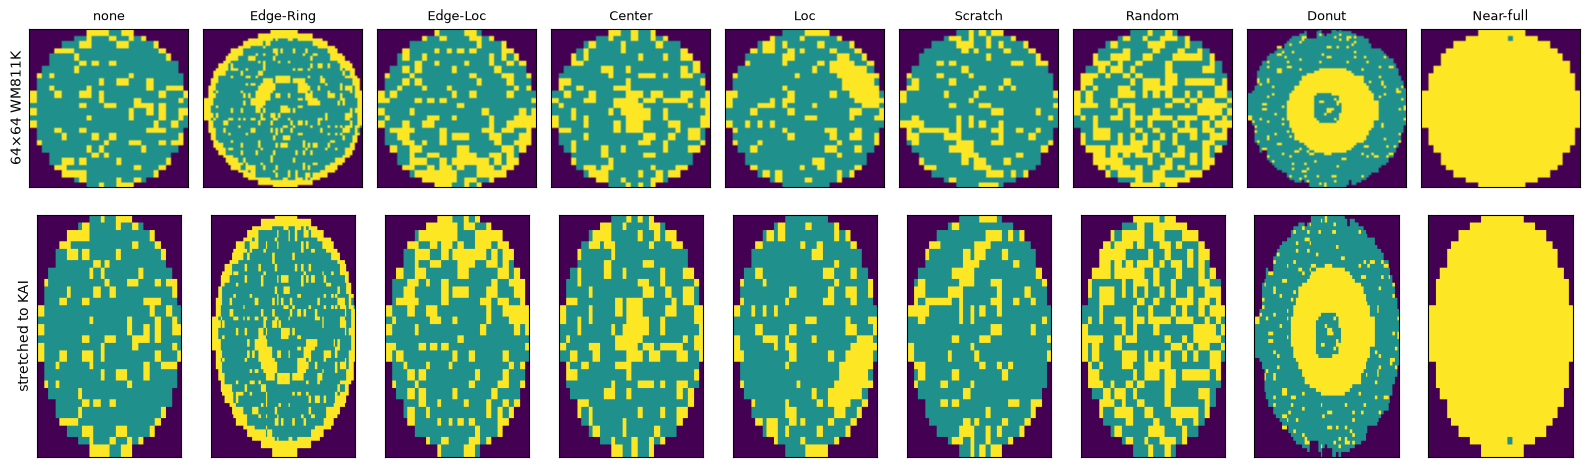

In [3]:
ex = [tr_idx[np.flatnonzero(y[tr_idx] == c)[0]] for c in WM811K_CLASSES]
kai = wm_to_kai(torch.tensor(X[ex])).argmax(1).numpy()
fig, ax = plt.subplots(2, 9, figsize=(16, 5))
for j, c in enumerate(WM811K_CLASSES):
    ax[0, j].imshow(X[ex[j]], cmap="viridis", vmin=0, vmax=2)
    ax[1, j].imshow(kai[j], cmap="viridis", vmin=0, vmax=2, origin="lower")
    ax[0, j].set_title(c, fontsize=9)
    for a in ax[:, j]:
        a.set_xticks([]); a.set_yticks([])
ax[0, 0].set_ylabel("64×64 WM811K")
ax[1, 0].set_ylabel("stretched to KAI")
plt.tight_layout()
plt.show()

## 2 · Train

epoch  1  loss 1.718  val macro-F1 0.335  (29s)


epoch  2  loss 1.468  val macro-F1 0.125  (31s)


epoch  3  loss 1.346  val macro-F1 0.403  (22s)


epoch  4  loss 1.245  val macro-F1 0.368  (19s)


epoch  5  loss 1.089  val macro-F1 0.368  (18s)


epoch  6  loss 1.156  val macro-F1 0.380  (18s)


... (5 outputs left out)

epoch 12  loss 0.767  val macro-F1 0.506  (18s)


epoch 13  loss 0.758  val macro-F1 0.574  (18s)


epoch 14  loss 0.717  val macro-F1 0.595  (18s)


epoch 15  loss 0.723  val macro-F1 0.576  (18s)


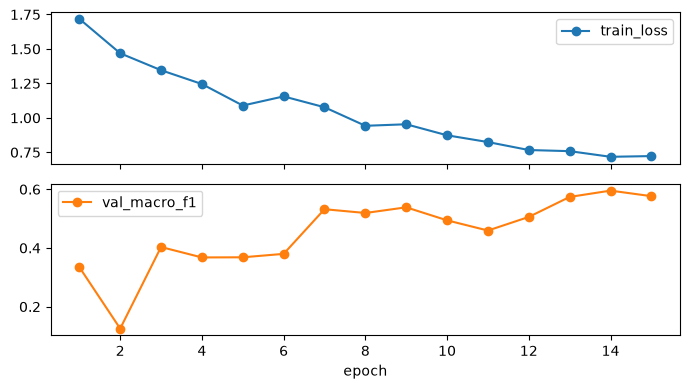

In [4]:
net, hist = pretrain_encoder(X, y, tr_idx, va_idx, epochs=EPOCHS, batch=64, lr=1e-3, seed=SEED)
hist = pd.DataFrame(hist).set_index("epoch")
hist.plot(subplots=True, figsize=(7, 4), marker="o")
plt.tight_layout()
plt.show()

## 3 · Validation (held-out WM811K lots)
Module 3 reported accuracy 0.939 and macro-F1 0.777 for its 64×64 CNN on a random split. This split
is grouped by lot, which is harder.

In [5]:
pred = predict_classes(net, torch.tensor(X, dtype=torch.uint8, device=DEVICE), va_idx)
yt = np.array([WM811K_CLASSES.index(c) for c in y[va_idx]])
print(classification_report(yt, pred, labels=range(9), target_names=WM811K_CLASSES, digits=3, zero_division=0))

              precision    recall  f1-score   support

        none      0.983     0.957     0.970      2583
   Edge-Ring      0.994     0.988     0.991       161
    Edge-Loc      0.875     0.673     0.761       104
      Center      0.300     0.545     0.387        33
         Loc      0.487     0.404     0.442        47
     Scratch      0.037     0.250     0.064        12
      Random      0.919     0.971     0.944        35
       Donut      0.000     0.000     0.000         1
   Near-full      0.667     1.000     0.800         2

    accuracy                          0.932      2978
   macro avg      0.585     0.643     0.595      2978
weighted avg      0.960     0.932     0.944      2978



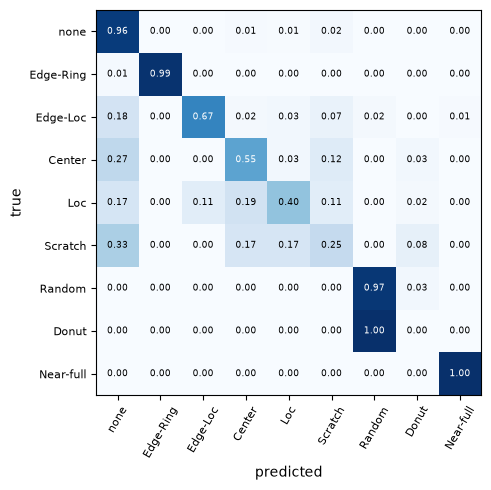

In [6]:
cm = confusion_matrix(yt, pred, labels=range(9), normalize="true")
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(9), WM811K_CLASSES, rotation=60, fontsize=8)
ax.set_yticks(range(9), WM811K_CLASSES, fontsize=8)
for i in range(9):
    for j in range(9):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=6.5, color="w" if cm[i, j] > 0.5 else "k")
ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout()
plt.show()

## 4 · Save the encoder weights

In [7]:
out = P.models / "encoder_wm811k.pt"
torch.save(net.encoder.state_dict(), out)
meta = {"epochs": EPOCHS, "best_val_macro_f1": float(hist["val_macro_f1"].max()),
        "best_epoch": int(hist["val_macro_f1"].idxmax()), "n_train": int(len(tr_idx)), "n_val": int(len(va_idx)),
        "input": "one-hot outside/pass/fail, 64x64 stretched to 193x115"}
(P.models / "encoder_wm811k.json").write_text(json.dumps(meta, indent=2))
print("saved", out, meta)

saved C:\Users\nsaba\OneDrive - Analog Devices, Inc\Documents\Chipagents\8803\Project\cache\models\encoder_wm811k.pt {'epochs': 15, 'best_val_macro_f1': 0.5953928290659336, 'best_epoch': 14, 'n_train': 15383, 'n_val': 2978, 'input': 'one-hot outside/pass/fail, 64x64 stretched to 193x115'}
